In [1]:
import numpy as np
import h5py
import os

In [2]:

filename = "../Results/SD3LMP/gaussian/Nodes_1024/gempy_data.h5"
with h5py.File(filename, "r") as f_data:
    c = f_data["input"][:]
    m_data = 2 * f_data["Gempy_output"][:]
    dmdc_data = 2 * f_data["Jacobian_Gempy"][:]


In [3]:

filename2 = "../Results/Deep_multi_layer_salt_dome/gaussian/Nodes_1024/gempy_data.h5"
with h5py.File(filename2, "r") as f_data2:
    c2 = f_data2["input"][:]
    m_data2 = 2 * f_data2["Gempy_output"][:]
    dmdc_data2 = 2 * f_data2["Jacobian_Gempy"][:]

FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = '../Results/Deep_multi_layer_salt_dome/gaussian/Nodes_1024/gempy_data.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [ ]:
dc = np.linalg.norm(c - c2)
relative_dc_error = dc / np.linalg.norm(c)
dc, relative_dc_error

(np.float64(0.0), np.float64(0.0))

In [ ]:
dm = np.linalg.norm(m_data - m_data2)
relative_dm_error = dm / np.linalg.norm(m_data)
dm, relative_dm_error

(np.float64(8.617162316333484e-11), np.float64(5.305943793542028e-15))

In [ ]:
d_dmdc = np.linalg.norm(dmdc_data - dmdc_data2)
relative_d_dmdc_error = d_dmdc / np.linalg.norm(dmdc_data)
d_dmdc, relative_d_dmdc_error

(np.float64(1.107015917417371e-08), np.float64(1.0452695667253786e-13))

In [ ]:
import h5py
import math
import os
nx=31
ny=31
nodes = (nx+1)*(ny+1)
current_folder = os.getcwd()
Sampling_type = "gaussian"
print("Sampling_type:", Sampling_type)
parent_folder = os.path.dirname(current_folder)
model_name = "SD3LMP"
print("Model name:", model_name)
directory_path = "../Results/"+str(model_name)+"/"+str(Sampling_type)+"/Nodes_"+str(nodes)
filename = directory_path + "/POD_eig.h5"
print(filename)

with h5py.File(filename, "r") as f_data:
    d_gaus = f_data["eigen-values"][:]

Sampling_type: gaussian
Model name: SD3LMP
../Results/SD3LMP/gaussian/Nodes_1024/POD_eig.h5


In [ ]:
Sampling_type = "uniform"
print("Sampling_type:", Sampling_type)
parent_folder = os.path.dirname(current_folder)
model_name = "SD3LMP"
print("Model name:", model_name)
directory_path = "../Results/"+str(model_name)+"/"+str(Sampling_type)+"/Nodes_"+str(nodes)
filename = directory_path + "/POD_eig.h5"
print(filename)

with h5py.File(filename, "r") as f_data_:
    d_uniform = f_data_["eigen-values"][:]

Sampling_type: uniform
Model name: SD3LMP
../Results/SD3LMP/uniform/Nodes_1024/POD_eig.h5


/var/folders/lr/h2867zhs72gcy61j6_cy0n0r0000gq/T/ipykernel_47280/1077495564.py:4: RuntimeWarning: invalid value encountered in log10
  plt.plot(np.arange(d_gaus.shape[0]), np.log10(d_gaus), label="Gaussian sampling")
/var/folders/lr/h2867zhs72gcy61j6_cy0n0r0000gq/T/ipykernel_47280/1077495564.py:5: RuntimeWarning: invalid value encountered in log10
  plt.plot(np.arange(d_uniform.shape[0]), np.log10(d_uniform), label="Uniform sampling")


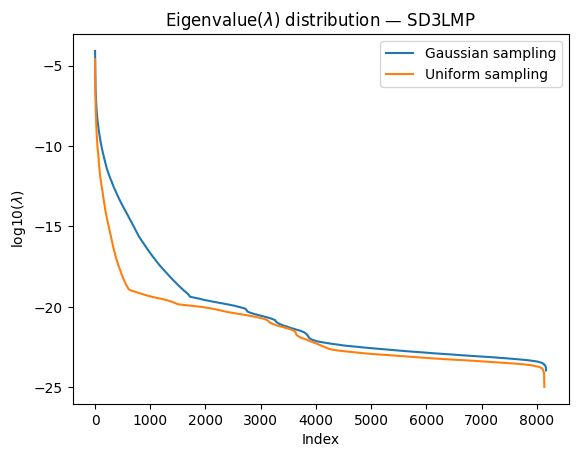

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.plot(np.arange(d_gaus.shape[0]), np.log10(d_gaus), label="Gaussian sampling")
plt.plot(np.arange(d_uniform.shape[0]), np.log10(d_uniform), label="Uniform sampling")
plt.xlabel("Index")
plt.ylabel(r"log10($\lambda$)")
plt.title(r"Eigenvalue($\lambda$) distribution — SD3LMP")
plt.legend()

# Jacobian accuracies data.

In [ ]:
r =          np.array([1,      5,      10,     20,     30,     40,     50,     60,     70,     80,     90,     100,    110,    120,    130,    140,    150])
J_uniform =  np.array([0.1989, 0.6427, 0.8179, 0.9034, 0.9422, 0.9651, 0.9756, 0.9835, 0.9890, 0.9919, 0.9938, 0.9951, 0.9961, 0.9969, 0.9974, 0.9979, 0.9983 ])
J_gaussian = np.array([0.1707, 0.5609, 0.7228 ,0.8214, 0.8647, 0.8937, 0.9142, 0.9294, 0.9406, 0.9493, 0.9567, 0.9624, 0.9671, 0.9715, 0.9751, 0.9781, 0.9808])

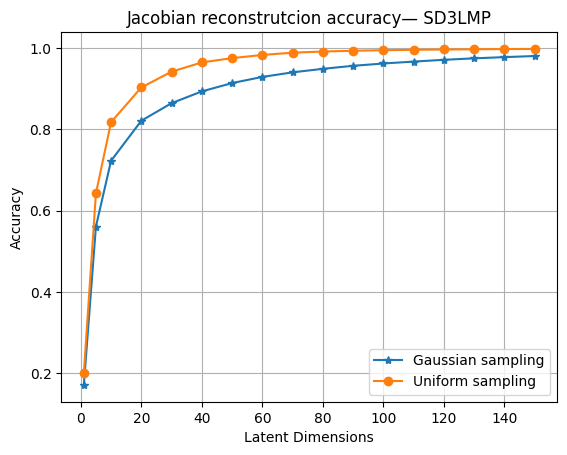

In [ ]:
plt.plot(r, J_gaussian, marker='*', label="Gaussian sampling")
plt.plot(r, J_uniform, marker='o', label="Uniform sampling")
plt.ylabel("Accuracy")
plt.xlabel("Latent Dimensions")
plt.title("Jacobian reconstrutcion accuracy— SD3LMP")
plt.grid()
plt.legend()
plt.show()

# Sample size vs Accuracies (Gaussian)
| N | λ=0 L1 (500)| λ=0  H1 (500)| λ=1 L1 (500) | λ=1 H1 (500)| Stage L1 (250) | Stage H1 (250) | Stage L1 (500) | Stage H1 (500) |
|---|---------|---------|---------|---------|----------------|----------------|----------------|----------------|
| 2^6  |0.9853 |0.2183| 0.9570|0.4761 |0.9822 |0.0858 | 0.9033| 0.4555|
| 2^7  |0.9842 |0.3454 |0.9696 |0.4652 |0.9853 |0.1967 | 0.9751|0.4795 |
| 2^8  |0.9867 |0.4203| 0.9785| 0.4905| 0.9857 | 0.3631| 0.9487 |0.5164|
| 2^9  |0.9905|0.4242| 0.9705| 0.5323| 0.9897| 0.4328| 0.9637| 0.5868|
| 2^10 |0.9905|0.4242| 0.9798| 0.5353|0.9884 |0.4349|0.9540 | 0.6571|
| 2^11 |0.9909|0.4058| 0.9568| 0.5095|0.9831 |0.3904 |0.9574 |0.5950|
| 2^12 |0.9931 |0.4630 |0.9616 |0.5246 | 0.9936|0.5197| 0.9853| 0.7192|
| 2^13 |0.9910| 0.3912| 0.9606| 0.7367|0.9931|0.5763|0.9457| 0.7583|

# Sample size vs Accuracies (uniform)
| N | λ=0 L1(500)| λ=0 H1(500)| λ=1 L1(500)| λ=1 H1(500)| Stage L1(250) | Stage H1(250) | Stage L1(500) | Stage H1(500) |
|---|---------|---------|---------|---------|----------------|----------------|----------------|----------------|
| 2^6  |0.9892 |0.1235 | 0.9633|0.5793|0.9863| 0.0264|0.9834 |0.5677|
| 2^7  |0.9923 |0.3164 | 0.9765|0.6237|0.9893| 0.1217|0.9749 |0.5918|
| 2^8  |0.9934 |0.5432 | 0.9847|0.6119|0.9911| 0.2737|0.9709 |0.6237|
| 2^9  |0.9951 |0.5786 | 0.9831|0.6768|0.9920| 0.5649|0.9521 |0.7203|
| 2^10 |0.9964 |0.5759 | 0.9826|0.7244|0.9948| 0.5788|0.9825 |0.7372|
| 2^11 |0.9971 |0.5804 | 0.9872|0.7389|0.9970| 0.5802|0.9885 |0.7737|
| 2^12 |0.9965 |0.5765 | 0.9775|0.7366|0.9966| 0.5731|0.9902 |0.8746|
| 2^13 |0.9964 |0.5755 | 0.9862|0.7861|0.9969| 0.5757|0.9978 |0.9366|

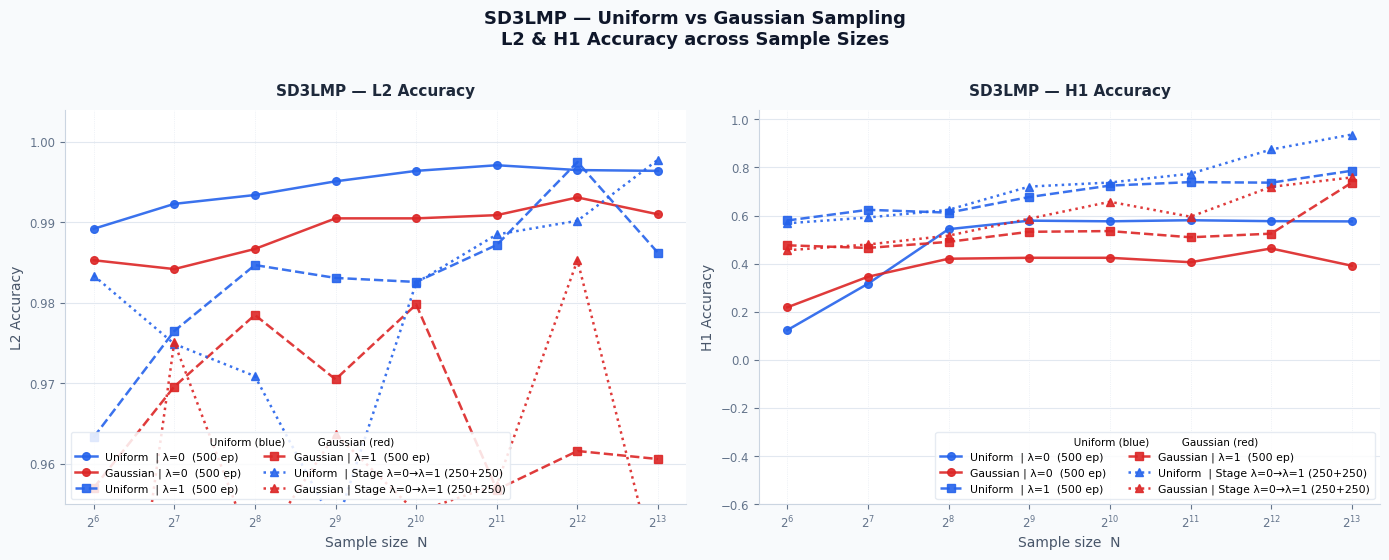

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

N_exp    = np.arange(6, 14)
x_labels = [f"$2^{{{i}}}$" for i in N_exp]
x        = np.arange(len(N_exp))

data = {
    "uniform": {
        "A_L2": [0.9892,0.9923,0.9934,0.9951,0.9964,0.9971,0.9965,0.9964], 
        "A_H1": [0.1235,0.3164,0.5432,0.5786,0.5759,0.5804,0.5765,0.5755],
        "B_L2": [0.9633,0.9765,0.9847,0.9831,0.9826,0.9872,0.9975,0.9862],
        "B_H1": [0.5793,0.6237,0.6119,0.6768,0.7244,0.7389,0.7366,0.7861],
        "C_L2": [0.9834,0.9749,0.9709,0.9521,0.9825,0.9885,0.9902,0.9978],
        "C_H1": [0.5677,0.5918,0.6237,0.7203,0.7372,0.7737,0.8746,0.9366],
    },
    "gaussian": {
        "A_L2": [0.9853,0.9842,0.9867,0.9905,0.9905,0.9909,0.9931,0.9910],
        "A_H1": [0.2183,0.3454,0.4203,0.4242,0.4242,0.4058,0.4630,0.3912],
        "B_L2": [0.9570,0.9696,0.9785,0.9705,0.9798,0.9568,0.9616,0.9606],
        "B_H1": [0.4761,0.4652,0.4905,0.5323,0.5353,0.5095,0.5246,0.7367],
        "C_L2": [0.9033,0.9751,0.9487,0.9637,0.9540,0.9574,0.9853,0.9457],
        "C_H1": [0.4555,0.4795,0.5164,0.5868,0.6571,0.5950,0.7192,0.7583],
    },
}

C_U = "#2563EB"   # blue  — uniform
C_G = "#DC2626"   # red   — gaussian

MODELS = [
    ("A", "λ=0  (500 ep)",           "-",  "o"),
    ("B", "λ=1  (500 ep)",           "--", "s"),
    ("C", "Stage λ=0→λ=1 (250+250)", ":",  "^"),
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
fig.patch.set_facecolor("#F8FAFC")

panel_cfg = [
    ("L2", "L2 Accuracy", (0.955, 1.004)),
    ("H1", "H1 Accuracy", (-0.60,  1.04)),
]

for ax, (metric, ylabel, ylim) in zip(axes, panel_cfg):
    ax.set_facecolor("#FFFFFF")
    ax.grid(axis="y", color="#E2E8F0", linewidth=0.8, zorder=0)
    ax.grid(axis="x", color="#E2E8F0", linewidth=0.5, linestyle=":", zorder=0)
    ax.spines[["top","right"]].set_visible(False)
    ax.spines[["left","bottom"]].set_color("#CBD5E1")

    for m_key, m_label, ls, marker in MODELS:
        y_u = np.array(data["uniform"] [f"{m_key}_{metric}"])
        y_g = np.array(data["gaussian"][f"{m_key}_{metric}"])

        ax.plot(x, y_u, color=C_U, linestyle=ls, marker=marker,
                markersize=5.5, linewidth=1.8, alpha=0.90,
                label=f"Uniform  | {m_label}")
        ax.plot(x, y_g, color=C_G, linestyle=ls, marker=marker,
                markersize=5.5, linewidth=1.8, alpha=0.90,
                label=f"Gaussian | {m_label}")

    ax.set_xticks(x)
    ax.set_xticklabels(x_labels, fontsize=9)
    ax.set_xlabel("Sample size  N", fontsize=10, color="#475569")
    ax.set_ylabel(ylabel, fontsize=10, color="#475569")
    ax.set_ylim(ylim)
    ax.tick_params(colors="#64748B", labelsize=8.5)
    ax.set_title(f"SD3LMP — {ylabel}", fontsize=11,
                 fontweight="bold", color="#1E293B", pad=10)

    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles, labels, ncol=2, fontsize=7.8,
              framealpha=0.85, edgecolor="#E2E8F0",
              loc="lower right" if metric == "H1" else "lower left",
              title="       Uniform (blue)          Gaussian (red)",
              title_fontsize=7.5)

fig.suptitle("SD3LMP — Uniform vs Gaussian Sampling\nL2 & H1 Accuracy across Sample Sizes",
             fontsize=13, fontweight="bold", color="#0F172A", y=1.01)

plt.tight_layout()
# plt.savefig("SD2LSP_L2_H1_comparison.png", dpi=160,
#             bbox_inches="tight", facecolor=fig.get_facecolor())
# plt.show()

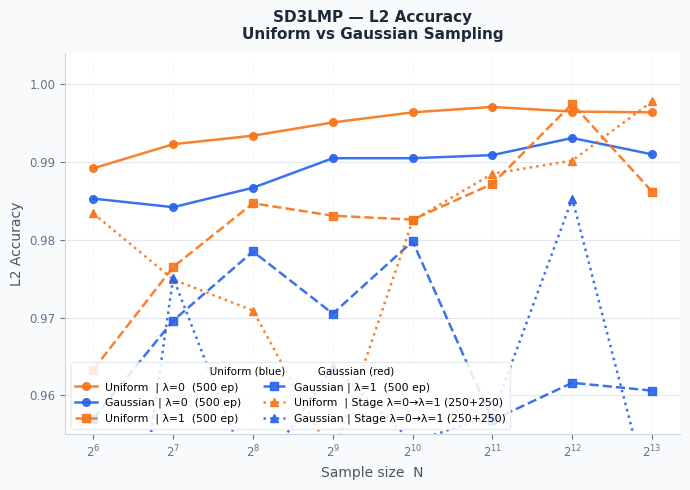

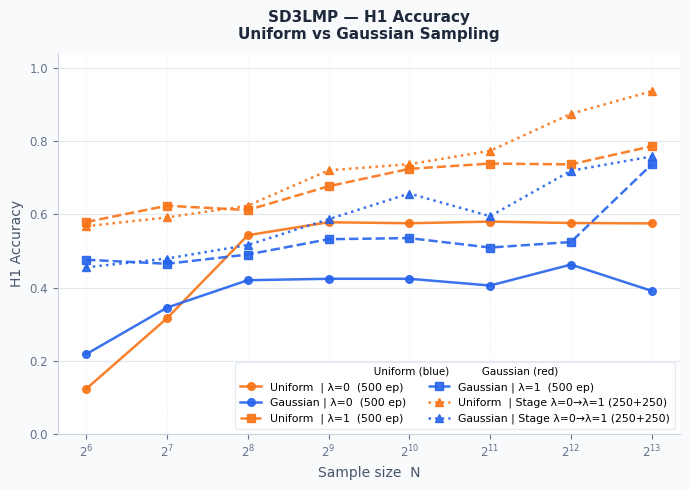

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

N_exp    = np.arange(6, 14)
x_labels = [f"$2^{{{i}}}$" for i in N_exp]
x        = np.arange(len(N_exp))

data = {
    "uniform": {
        "A_L2": [0.9892,0.9923,0.9934,0.9951,0.9964,0.9971,0.9965,0.9964], 
        "A_H1": [0.1235,0.3164,0.5432,0.5786,0.5759,0.5804,0.5765,0.5755],
        "B_L2": [0.9633,0.9765,0.9847,0.9831,0.9826,0.9872,0.9975,0.9862],
        "B_H1": [0.5793,0.6237,0.6119,0.6768,0.7244,0.7389,0.7366,0.7861],
        "C_L2": [0.9834,0.9749,0.9709,0.9521,0.9825,0.9885,0.9902,0.9978],
        "C_H1": [0.5677,0.5918,0.6237,0.7203,0.7372,0.7737,0.8746,0.9366],
    },
    "gaussian": {
        "A_L2": [0.9853,0.9842,0.9867,0.9905,0.9905,0.9909,0.9931,0.9910],
        "A_H1": [0.2183,0.3454,0.4203,0.4242,0.4242,0.4058,0.4630,0.3912],
        "B_L2": [0.9570,0.9696,0.9785,0.9705,0.9798,0.9568,0.9616,0.9606],
        "B_H1": [0.4761,0.4652,0.4905,0.5323,0.5353,0.5095,0.5246,0.7367],
        "C_L2": [0.9033,0.9751,0.9487,0.9637,0.9540,0.9574,0.9853,0.9457],
        "C_H1": [0.4555,0.4795,0.5164,0.5868,0.6571,0.5950,0.7192,0.7583],
    },
}

C_G = "#2563EB"   # blue  — gaussian
C_U = "#F97316"   # red   — uniform

MODELS = [
    ("A", "λ=0  (500 ep)",            "-",  "o"),
    ("B", "λ=1  (500 ep)",            "--", "s"),
    ("C", "Stage λ=0→λ=1 (250+250)",  ":",  "^"),
]

panel_cfg = [
    ("L2", "L2 Accuracy", (0.955, 1.004), "lower left",  "SD3LMP_L2.png"),
    ("H1", "H1 Accuracy", (-0.0,  1.04), "lower right", "SD3LMP_H1.png"),
]

for metric, ylabel, ylim, legend_loc, fname in panel_cfg:

    fig, ax = plt.subplots(figsize=(7, 5))
    fig.patch.set_facecolor("#F8FAFC")
    ax.set_facecolor("#FFFFFF")
    ax.grid(axis="y", color="#E2E8F0", linewidth=0.8, zorder=0)
    ax.grid(axis="x", color="#E2E8F0", linewidth=0.5, linestyle=":", zorder=0)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#CBD5E1")

    for m_key, m_label, ls, marker in MODELS:
        y_u = np.array(data["uniform"] [f"{m_key}_{metric}"])
        y_g = np.array(data["gaussian"][f"{m_key}_{metric}"])

        ax.plot(x, y_u, color=C_U, linestyle=ls, marker=marker,
                markersize=5.5, linewidth=1.8, alpha=0.90,
                label=f"Uniform  | {m_label}")
        ax.plot(x, y_g, color=C_G, linestyle=ls, marker=marker,
                markersize=5.5, linewidth=1.8, alpha=0.90,
                label=f"Gaussian | {m_label}")

    ax.set_xticks(x)
    ax.set_xticklabels(x_labels, fontsize=9)
    ax.set_xlabel("Sample size  N", fontsize=10, color="#475569")
    ax.set_ylabel(ylabel, fontsize=10, color="#475569")
    ax.set_ylim(ylim)
    ax.tick_params(colors="#64748B", labelsize=8.5)
    ax.set_title(f"SD3LMP — {ylabel}\nUniform vs Gaussian Sampling",
                 fontsize=11, fontweight="bold", color="#1E293B", pad=10)

    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles, labels, ncol=2, fontsize=7.8,
              framealpha=0.85, edgecolor="#E2E8F0",
              loc=legend_loc,
              title="       Uniform (blue)          Gaussian (red)",
              title_fontsize=7.5)

    plt.tight_layout()
    plt.savefig(fname, dpi=160, bbox_inches="tight",
                facecolor=fig.get_facecolor())
    plt.show()   # displays inline in the notebook
    plt.close()
    #print(f"Saved {fname}")